In [28]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')


In [29]:
#upload dataset
df=pd.read_csv('/content/customer_behavior.csv')
df.shape


(5000, 7)

In [8]:
df.head()

,CustomerID,Gender,Region,PurchaseAmount,ProductCategory,Churn,CampaignGroup
0,1001,Male,South,256.07,Fashion,No,A
1,1002,Female,South,NaN,Electronics,Yes,B
2,1003,Female,West,1194.41,Fashion,No,A
3,1004,Female,South,413.06,Grocery,No,A
4,1005,Male,West,1556.32,Fashion,Yes,A


In [9]:
# Calculate mean, median, and mode of PurchaseAmount
mean_val = df['PurchaseAmount'].mean()
median_val = df['PurchaseAmount'].median()
mode_val = df['PurchaseAmount'].mode()[0]

print(f'Average (Mean): {mean_val}')
print(f'Median: {median_val}')
print(f'Mode: {mode_val}')

Average (Mean): 1003.9506701030928
Median: 998.0799999999999
Mode: 0.0


In [10]:
# Calculate IQR to detect outliers
q1 = df['PurchaseAmount'].quantile(0.25)
q3 = df['PurchaseAmount'].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df[(df['PurchaseAmount'] < lower_bound) | (df['PurchaseAmount'] > upper_bound)]

print(f"Q1 (25th percentile): {q1}")
print(f"Q3 (75th percentile): {q3}")
print(f"IQR: {iqr}")
print(f"Lower Bound (for outliers): {lower_bound}")
print(f"Upper Bound (for outliers): {upper_bound}")
print(f"Number of statistical outliers: {outliers.shape[0]}")

Q1 (25th percentile): 673.6424999999999
Q3 (75th percentile): 1327.0775
IQR: 653.4350000000002
Lower Bound (for outliers): -306.51000000000033
Upper Bound (for outliers): 2307.2300000000005
Number of statistical outliers: 15


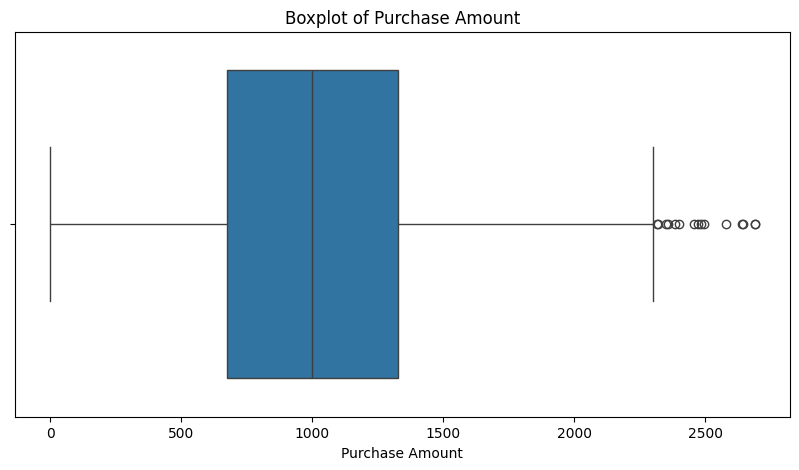

In [11]:
# Visualize PurchaseAmount with a boxplot to identify outliers
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['PurchaseAmount'])
plt.title('Boxplot of Purchase Amount')
plt.xlabel('Purchase Amount')
plt.show()

In [12]:
# Calculate skewness and kurtosis
skew_val = df['PurchaseAmount'].skew()
kurt_val = df['PurchaseAmount'].kurt()

print(f"Skewness: {skew_val}")
print(f"Kurtosis: {kurt_val}")

Skewness: 0.10609189374631554
Kurtosis: -0.2615105545319705


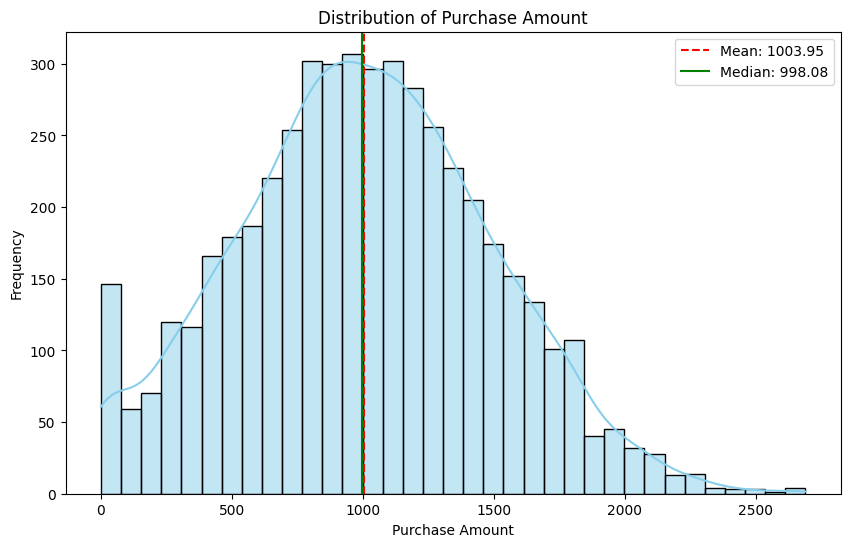

In [13]:
# Plot the distribution of PurchaseAmount
plt.figure(figsize=(10, 6))
sns.histplot(df['PurchaseAmount'].dropna(), kde=True, color='skyblue')
plt.title('Distribution of Purchase Amount')
plt.xlabel('Purchase Amount')
plt.ylabel('Frequency')
plt.axvline(mean_val, color='red', linestyle='--', label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color='green', linestyle='-', label=f'Median: {median_val:.2f}')
plt.legend()
plt.show()

In [14]:
# Split data into male and female spending, dropping missing values
male_spending = df[df['Gender'] == 'Male']['PurchaseAmount'].dropna()
female_spending = df[df['Gender'] == 'Female']['PurchaseAmount'].dropna()

# Calculate basic statistics
print(f"Male Customers - Count: {len(male_spending)}, Mean: {male_spending.mean():.2f}, Median: {male_spending.median():.2f}")
print(f"Female Customers - Count: {len(female_spending)}, Mean: {female_spending.mean():.2f}, Median: {female_spending.median():.2f}")

# Perform independent 2-sample t-test
t_stat, p_val = stats.ttest_ind(male_spending, female_spending, equal_var=False)
print(f"\nt-statistic: {t_stat:.4f}")
print(f"p-value: {p_val:.4f}")

if p_val < 0.05:
    print("Result: There is a statistically SIGNIFICANT difference in spending between genders (p < 0.05).")
else:
    print("Result: There is NO statistically significant difference in spending between genders (p >= 0.05).")

Male Customers - Count: 2386, Mean: 1019.18, Median: 1011.21
Female Customers - Count: 2370, Mean: 987.87, Median: 983.00

t-statistic: 2.2348
p-value: 0.0255
Result: There is a statistically SIGNIFICANT difference in spending between genders (p < 0.05).


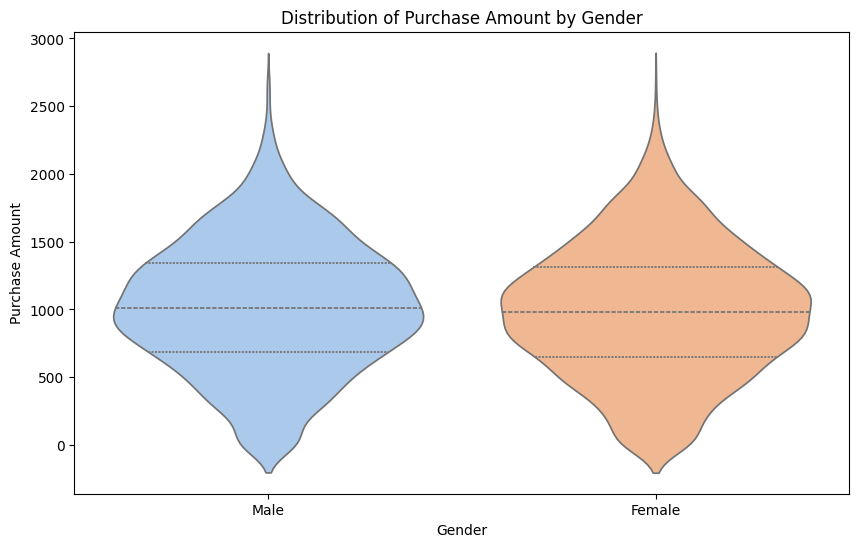

In [15]:
# Visualize spending difference using boxplot and violin plot
plt.figure(figsize=(10, 6))
sns.violinplot(x='Gender', y='PurchaseAmount', data=df, inner='quartile', palette='pastel')
plt.title('Distribution of Purchase Amount by Gender')
plt.xlabel('Gender')
plt.ylabel('Purchase Amount')
plt.show()

In [16]:
# Create a contingency table (cross-tabulation) of ProductCategory and Churn
contingency_table = pd.crosstab(df['ProductCategory'], df['Churn'])
print("Contingency Table:")
display(contingency_table)

# Calculate percentages to see proportions
contingency_pct = pd.crosstab(df['ProductCategory'], df['Churn'], normalize='index') * 100
print("\nChurn Percentages by Product Category (%):")
display(contingency_pct)

# Perform Chi-Square Test of Independence
chi2, p_val, dof, expected = stats.chi2_contingency(contingency_table)
print(f"\nChi-Square Statistic: {chi2:.4f}")
print(f"p-value: {p_val:.4f}")

if p_val < 0.05:
    print("\nResult: There is a statistically SIGNIFICANT relationship between ProductCategory and Churn (p < 0.05).")
else:
    print("\nResult: There is NO statistically significant relationship between ProductCategory and Churn (p >= 0.05).")

Contingency Table:


Churn,No,Yes
ProductCategory,,
Electronics,785,541
Fashion,839,607
Grocery,855,604



Churn Percentages by Product Category (%):


Churn,No,Yes
ProductCategory,,
Electronics,59.200603,40.799397
Fashion,58.022130,41.977870
Grocery,58.601782,41.398218



Chi-Square Statistic: 0.3960
p-value: 0.8204

Result: There is NO statistically significant relationship between ProductCategory and Churn (p >= 0.05).


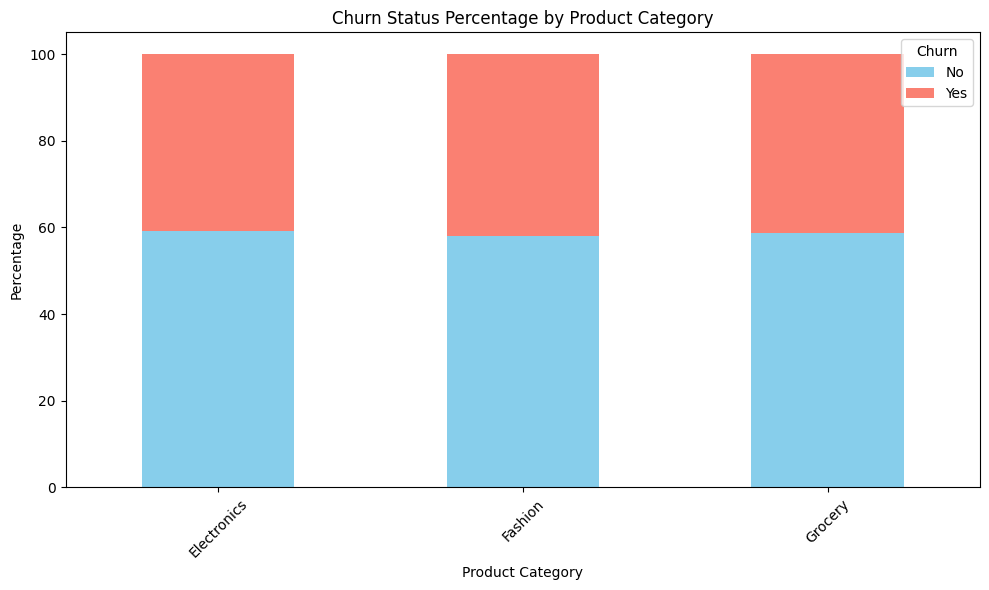

In [17]:
# Visualize the relationship with a 100% stacked bar chart
contingency_pct.plot(kind='bar', stacked=True, figsize=(10, 6), color=['skyblue', 'salmon'])
plt.title('Churn Status Percentage by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Percentage')
plt.legend(title='Churn', loc='upper right')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
# Drop missing values for Region and PurchaseAmount to prepare groups
clean_df = df[['Region', 'PurchaseAmount']].dropna()

# Get list of unique regions
regions = clean_df['Region'].unique()
print(f"Regions found: {regions}\n")

# Group purchase amounts by region
region_groups = [clean_df[clean_df['Region'] == r]['PurchaseAmount'] for r in regions]

# Calculate basic descriptive stats per region
region_stats = clean_df.groupby('Region')['PurchaseAmount'].agg(['count', 'mean', 'median', 'std'])
print("Descriptive Statistics by Region:")
display(region_stats)

# Perform One-way ANOVA
f_stat, p_val_anova = stats.f_oneway(*region_groups)
print(f"\nOne-way ANOVA F-statistic: {f_stat:.4f}")
print(f"p-value: {p_val_anova:.4f}")

if p_val_anova < 0.05:
    print("Result: There is a statistically SIGNIFICANT difference in PurchaseAmount across different regions (p < 0.05).")
else:
    print("Result: There is NO statistically significant difference in PurchaseAmount across different regions (p >= 0.05).")

Regions found: ['South' 'West' 'North' 'East']

Descriptive Statistics by Region:


,count,mean,median,std
Region,,,,
East,1195,1009.946017,1006.290,490.355691
North,1167,1013.017952,1000.160,467.897373
South,1202,997.603877,1000.935,484.095616
West,1115,995.247327,985.160,485.801447



One-way ANOVA F-statistic: 0.3897
p-value: 0.7605
Result: There is NO statistically significant difference in PurchaseAmount across different regions (p >= 0.05).


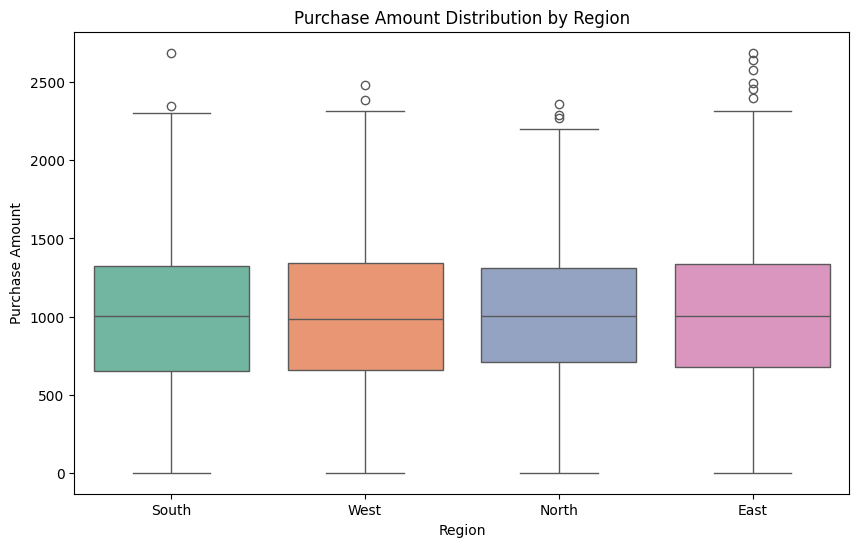

In [19]:
# Visualize PurchaseAmount across regions using a boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x='Region', y='PurchaseAmount', data=df, palette='Set2')
plt.title('Purchase Amount Distribution by Region')
plt.xlabel('Region')
plt.ylabel('Purchase Amount')
plt.show()

In [21]:
# Group by CampaignGroup and calculate mean, count, and median PurchaseAmount
campaign_stats = df.groupby('CampaignGroup')['PurchaseAmount'].agg(['count', 'mean', 'median', 'std'])
print("Campaign Performance Statistics:")
display(campaign_stats)

# Split data to perform a t-test
cohort_a = df[df['CampaignGroup'] == 'A']['PurchaseAmount'].dropna()
cohort_b = df[df['CampaignGroup'] == 'B']['PurchaseAmount'].dropna()

t_stat, p_val = stats.ttest_ind(cohort_a, cohort_b, equal_var=False)
print(f"\nt-statistic: {t_stat:.4f}")
print(f"p-value: {p_val:.4f}")

if p_val < 0.05:
    print("\nResult: The difference in average PurchaseAmount between Campaign A and B is statistically SIGNIFICANT (p < 0.05).")
else:
    print("\nResult: The difference in average PurchaseAmount between Campaign A and B is NOT statistically significant (p >= 0.05).")

Campaign Performance Statistics:


,count,mean,median,std
CampaignGroup,,,,
A,2350,1011.945587,1010.155,480.160915
B,2318,994.339965,977.235,487.383742



t-statistic: 1.2431
p-value: 0.2139

Result: The difference in average PurchaseAmount between Campaign A and B is NOT statistically significant (p >= 0.05).


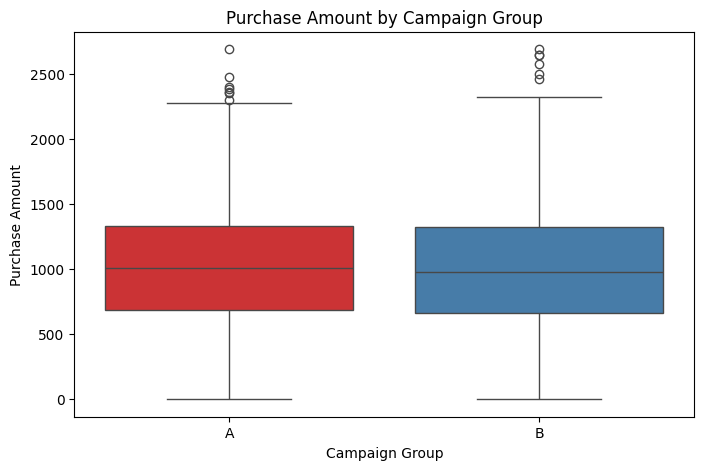

In [22]:
# Visualize Campaign Performance using a boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(x='CampaignGroup', y='PurchaseAmount', data=df, palette='Set1')
plt.title('Purchase Amount by Campaign Group')
plt.xlabel('Campaign Group')
plt.ylabel('Purchase Amount')
plt.show()

In [23]:
# Perform D'Agostino's K-squared test for normality (suitable for larger sample sizes)
k2_stat, p_val_norm = stats.normaltest(df['PurchaseAmount'].dropna())
print(f"D'Agostino's K-squared Test:")
print(f"Statistic: {k2_stat:.4f}")
print(f"p-value: {p_val_norm:.4f}")

if p_val_norm < 0.05:
    print("\nResult: We REJECT the null hypothesis (p < 0.05). The data does NOT follow a normal distribution.")
else:
    print("\nResult: We FAIL to reject the null hypothesis (p >= 0.05). The data is consistent with a normal distribution.")

D'Agostino's K-squared Test:
Statistic: 27.2516
p-value: 0.0000

Result: We REJECT the null hypothesis (p < 0.05). The data does NOT follow a normal distribution.


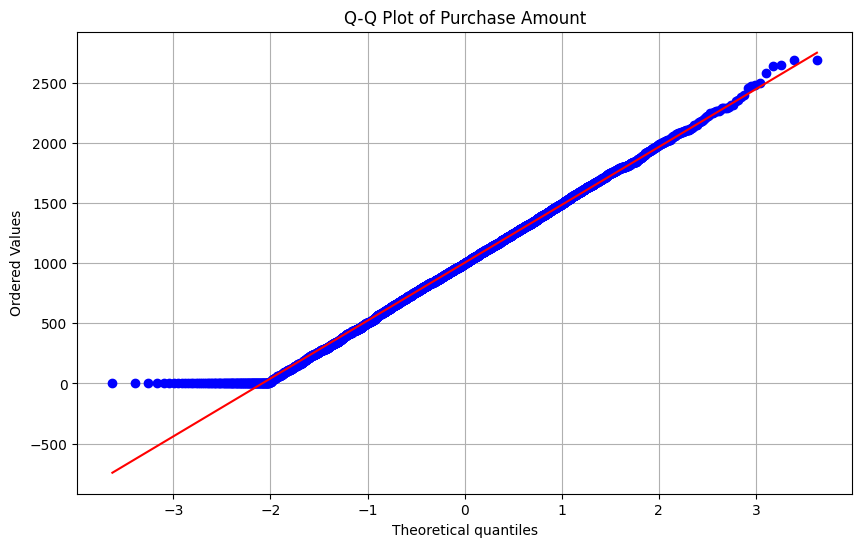

In [25]:
# Generate a Q-Q plot to visually assess normality
plt.figure(figsize=(10, 6))
stats.probplot(df['PurchaseAmount'].dropna(), dist="norm", plot=plt)
plt.title('Q-Q Plot of Purchase Amount')
plt.grid(True)
plt.show()

### Demonstrating the Central Limit Theorem (CLT)
We will now write a simulation to demonstrate the CLT. We will:
1. Draw 1,000 random samples of size $n = 5$ and calculate their means.
2. Draw 1,000 random samples of size $n = 30$ and calculate their means.
3. Draw 1,000 random samples of size $n = 100$ and calculate their means.
4. Plot the distribution of these sample means to see how they approximate a normal distribution as $n$ grows.

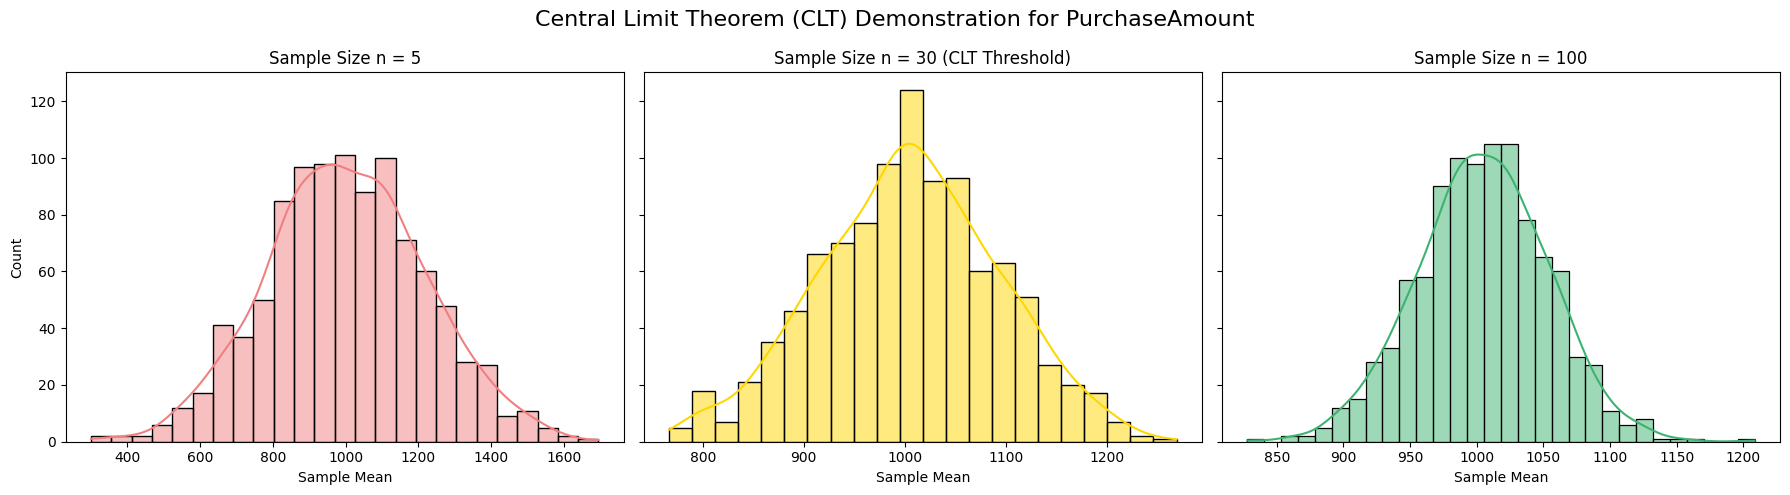

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Drop missing values to get clean population data
population = df['PurchaseAmount'].dropna()

# Set random seed for reproducibility
np.random.seed(42)

# Function to generate sample means
def get_sample_means(data, sample_size, num_samples=1000):
    return [data.sample(n=sample_size, replace=True).mean() for _ in range(num_samples)]

# Generate sample means for different sample sizes
means_n5 = get_sample_means(population, sample_size=5)
means_n30 = get_sample_means(population, sample_size=30)
means_n100 = get_sample_means(population, sample_size=100)

# Plot the distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

sns.histplot(means_n5, kde=True, ax=axes[0], color='lightcoral')
axes[0].set_title('Sample Size n = 5')
axes[0].set_xlabel('Sample Mean')

sns.histplot(means_n30, kde=True, ax=axes[1], color='gold')
axes[1].set_title('Sample Size n = 30 (CLT Threshold)')
axes[1].set_xlabel('Sample Mean')

sns.histplot(means_n100, kde=True, ax=axes[2], color='mediumseagreen')
axes[2].set_title('Sample Size n = 100')
axes[2].set_xlabel('Sample Mean')

plt.suptitle('Central Limit Theorem (CLT) Demonstration for PurchaseAmount', fontsize=16)
plt.tight_layout()
plt.show()

### 95% Confidence Interval for the Average PurchaseAmount
To find the range in which we can be 95% confident the true population average lies, we will calculate the confidence interval using the sample mean, standard error, and the t-distribution critical value (since the population standard deviation is unknown).

In [27]:
# Get clean purchase amount data
purchases = df['PurchaseAmount'].dropna()

# Calculate sample statistics
n = len(purchases)
mean = purchases.mean()
std_err = stats.sem(purchases) # Standard error of the mean (std / sqrt(n))

# Calculate the 95% confidence interval
confidence_level = 0.95
ci = stats.t.interval(confidence_level, df=n-1, loc=mean, scale=std_err)

print(f"Sample Size (n): {n}")
print(f"Sample Mean: {mean:.2f}")
print(f"Standard Error: {std_err:.4f}")
print(f"95% Confidence Interval: ({ci[0]:.2f}, {ci[1]:.2f})")

Sample Size (n): 4850
Sample Mean: 1003.95
Standard Error: 6.9227
95% Confidence Interval: (990.38, 1017.52)
